## Задание 3.2 Keras: Свёрточные сети (CNN)
Изучите доступные типы слоёв в Keras и принципы построения свёрточных сетей.
Загрузите встроенный набор картинок cifar10.
Создайте и обучите несколько моделей свёрточных нейросетей.
Оцените результаты.

In [1]:
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt

In [2]:
import numpy as np
import seaborn as sns
import pandas as pd

In [3]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()

In [4]:
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

/var/folders/8_/ss2c3myd785fm4m9w3q294100000gn/T/ipykernel_861/3911883463.py:6: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  plt.title(class_names[int(y_train[i])])


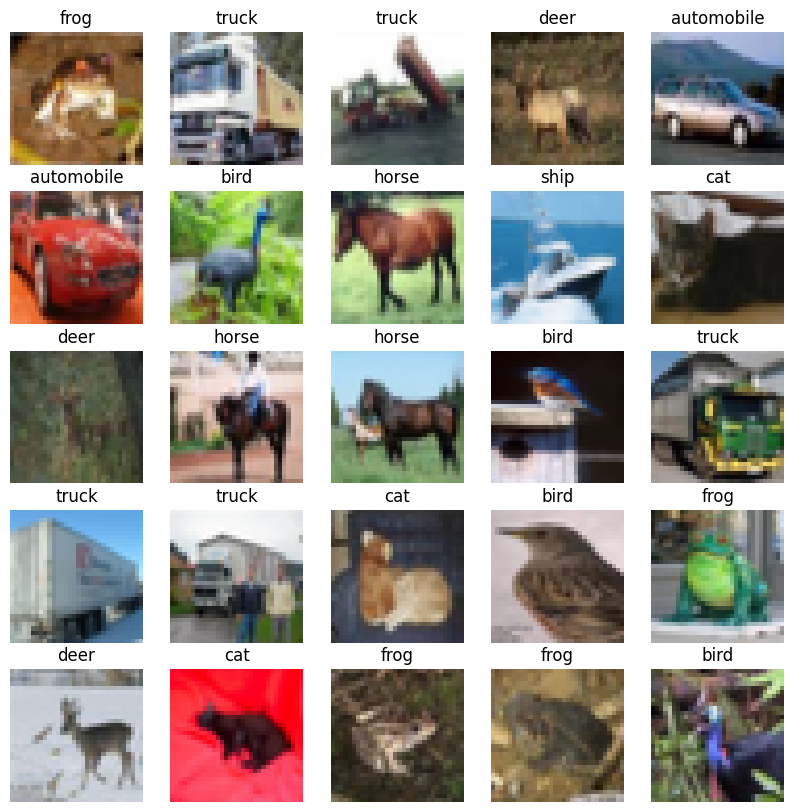

In [5]:
plt.figure(figsize=(10,10))

for i in range(25):
    plt.subplot(5,5,i+1)
    plt.imshow(x_train[i])
    plt.title(class_names[int(y_train[i])])
    plt.axis('off')

plt.show()

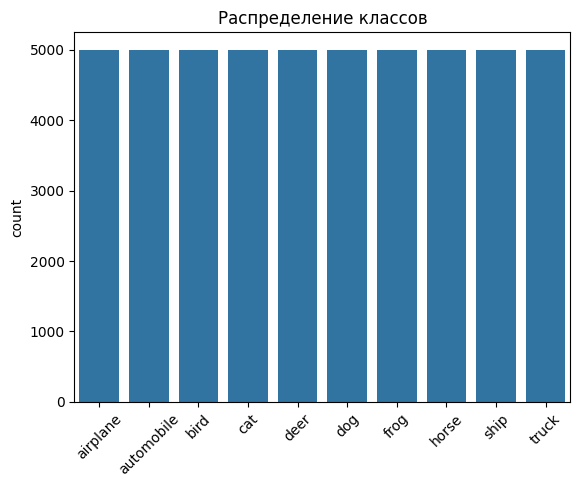

In [6]:
sns.countplot(x=y_train.flatten())
plt.xticks(range(10), class_names, rotation=45)
plt.title("Распределение классов")
plt.show()

In [7]:
x_train = x_train / 255.0
x_test = x_test / 255.0

In [8]:
x_train.shape

(50000, 32, 32, 3)

### Simple CNN (простая модель)

Simple CNN — базовая свёрточная сеть (Conv2D + MaxPooling + Dense).     
CNN + Dropout — добавлен Dropout для борьбы с переобучением.        
CNN + BatchNorm — добавлена Batch Normalization для ускорения и стабилизации обучения.      

Каждая модель:

компилируется (adam, sparse_categorical_crossentropy);      
обучается (model.fit на 10–20 эпохах).

In [9]:
model_1 = models.Sequential([
    layers.Conv2D(32, (3,3), activation='relu', input_shape=(32,32,3)),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),

    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [10]:
model_1.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [11]:
history_1 = model_1.fit(
    x_train, y_train,
    epochs=10,
    validation_data=(x_test, y_test)
)

Epoch 1/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 33s 20ms/step - accuracy: 0.4659 - loss: 1.4834 - val_accuracy: 0.5721 - val_loss: 1.2081
Epoch 2/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 29s 19ms/step - accuracy: 0.6049 - loss: 1.1296 - val_accuracy: 0.6213 - val_loss: 1.0791
Epoch 3/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 20s 13ms/step - accuracy: 0.6515 - loss: 1.0026 - val_accuracy: 0.6572 - val_loss: 0.9807
Epoch 4/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 21s 13ms/step - accuracy: 0.6808 - loss: 0.9205 - val_accuracy: 0.6660 - val_loss: 0.9687
Epoch 5/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 21s 14ms/step - accuracy: 0.7041 - loss: 0.8551 - val_accuracy: 0.6839 - val_loss: 0.9158
Epoch 6/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 22s 14ms/step - accuracy: 0.7236 - loss: 0.8032 - val_accuracy: 0.6804 - val_loss: 0.9394
Epoch 7/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 22s 14ms/step - accuracy: 0.7385 - loss: 0.7561 - val_accuracy: 0.6715 - val_loss: 0.9478
Epoch 8/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 21s 14ms/step - accuracy: 0.7547 -

### Улучшенная CNN (глубже + Dropout)

In [12]:
model_2 = models.Sequential([
    layers.Conv2D(32, (3,3), activation='relu', padding='same', input_shape=(32,32,3)),
    layers.Conv2D(32, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),
    layers.Dropout(0.25),

    layers.Conv2D(64, (3,3), activation='relu', padding='same'),
    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),
    layers.Dropout(0.25),

    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(10, activation='softmax')
])

In [13]:
model_2.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [14]:
history_2 = model_2.fit(
    x_train, y_train,
    epochs=10,
    validation_data=(x_test, y_test)
)

Epoch 1/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 65s 41ms/step - accuracy: 0.4034 - loss: 1.6233 - val_accuracy: 0.5342 - val_loss: 1.2668
Epoch 2/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 73s 47ms/step - accuracy: 0.5409 - loss: 1.2858 - val_accuracy: 0.6042 - val_loss: 1.1321
Epoch 3/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 77s 49ms/step - accuracy: 0.6023 - loss: 1.1280 - val_accuracy: 0.6592 - val_loss: 0.9825
Epoch 4/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 66s 42ms/step - accuracy: 0.6385 - loss: 1.0302 - val_accuracy: 0.6917 - val_loss: 0.8714
Epoch 5/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 63s 40ms/step - accuracy: 0.6672 - loss: 0.9605 - val_accuracy: 0.7096 - val_loss: 0.8362
Epoch 6/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 70s 45ms/step - accuracy: 0.6809 - loss: 0.9131 - val_accuracy: 0.7143 - val_loss: 0.8206
Epoch 7/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 66s 42ms/step - accuracy: 0.6920 - loss: 0.8781 - val_accuracy: 0.7292 - val_loss: 0.7796
Epoch 8/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 63s 40ms/step - accuracy: 0.7026 -

### Ещё одна модель (с BatchNormalization)

In [30]:
model_3 = models.Sequential([
    layers.Conv2D(32, (3,3), padding='same', input_shape=(32,32,3)),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D(),

    layers.Conv2D(64, (3,3), padding='same'),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D(),

    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(10, activation='softmax')
])

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [31]:
model_3.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [32]:
history_3 = model_3.fit(
    x_train, y_train,
    epochs=10,
    validation_data=(x_test, y_test)
)

Epoch 1/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 61s 38ms/step - accuracy: 0.5007 - loss: 1.4033 - val_accuracy: 0.5472 - val_loss: 1.3233
Epoch 2/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 46s 30ms/step - accuracy: 0.6470 - loss: 1.0013 - val_accuracy: 0.6333 - val_loss: 1.0394
Epoch 3/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 48s 31ms/step - accuracy: 0.6863 - loss: 0.8880 - val_accuracy: 0.6296 - val_loss: 1.0687
Epoch 4/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 41s 26ms/step - accuracy: 0.7170 - loss: 0.8095 - val_accuracy: 0.6771 - val_loss: 0.9255
Epoch 5/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 40s 26ms/step - accuracy: 0.7415 - loss: 0.7396 - val_accuracy: 0.6623 - val_loss: 1.0094
Epoch 6/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 40s 26ms/step - accuracy: 0.7614 - loss: 0.6872 - val_accuracy: 0.7141 - val_loss: 0.8589
Epoch 7/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 42s 27ms/step - accuracy: 0.7775 - loss: 0.6404 - val_accuracy: 0.6353 - val_loss: 1.1550
Epoch 8/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 42s 27ms/step - accuracy: 0.7896 -

### Оценка моделей

In [33]:
test_loss_1, test_acc_1 = model_1.evaluate(x_test, y_test)
test_loss_2, test_acc_2 = model_2.evaluate(x_test, y_test)
test_loss_3, test_acc_3 = model_3.evaluate(x_test, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7021 - loss: 0.9178
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.7477 - loss: 0.7281
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.6835 - loss: 1.0025


In [34]:
test_acc_1

0.7020999789237976

In [35]:
test_acc_2

0.7476999759674072

In [36]:
test_acc_3

0.6834999918937683

### Визуализация обучения

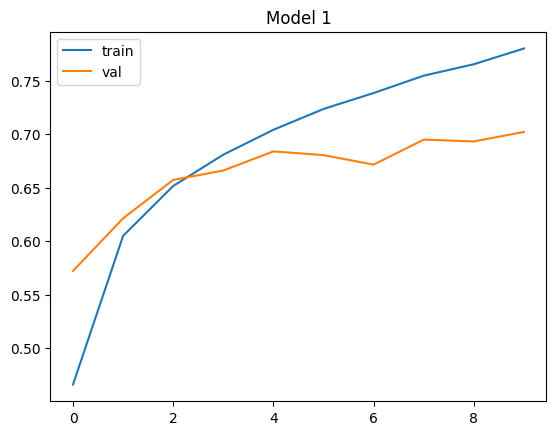

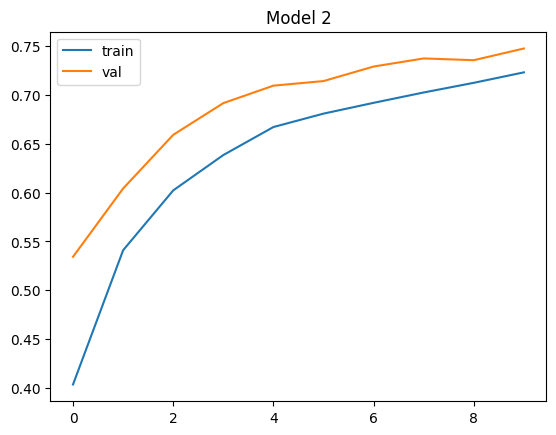

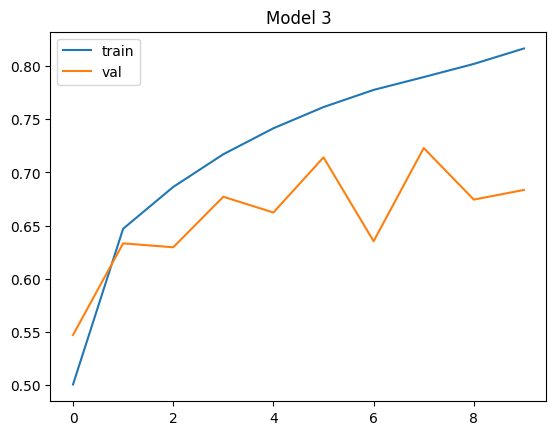

In [37]:
def plot_history(history, title):
    plt.plot(history.history['accuracy'], label='train')
    plt.plot(history.history['val_accuracy'], label='val')
    plt.title(title)
    plt.legend()
    plt.show()

plot_history(history_1, "Model 1")
plot_history(history_2, "Model 2")
plot_history(history_3, "Model 3")

In [38]:
predictions = model_2.predict(x_test)
pred_labels = np.argmax(predictions, axis=1)

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step


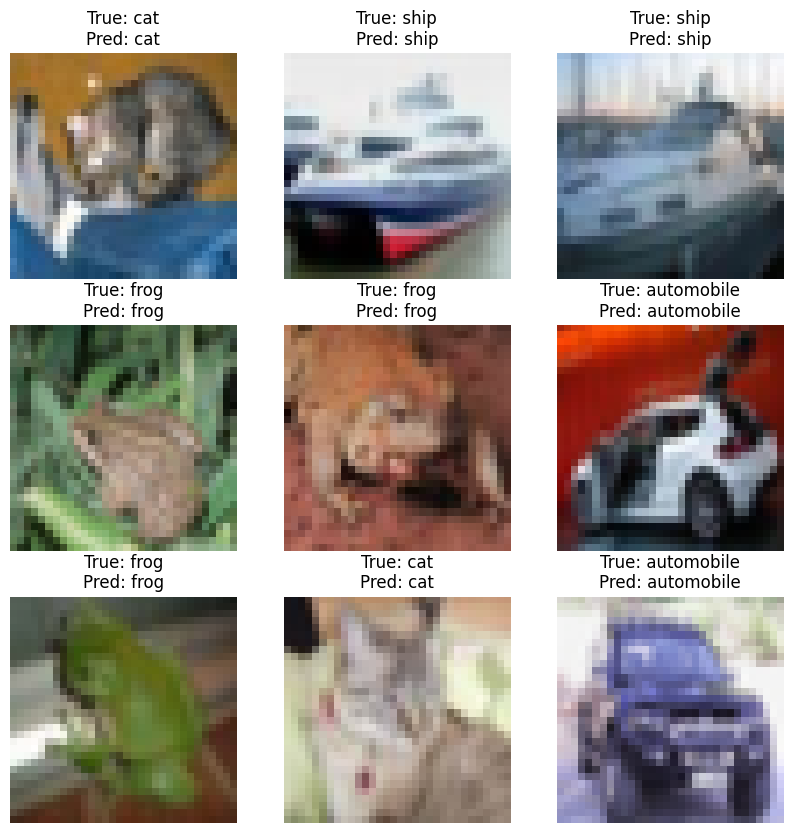

In [39]:
plt.figure(figsize=(10,10))

correct = np.where(pred_labels == y_test.flatten())[0]

for i, idx in enumerate(correct[:9]):
    plt.subplot(3,3,i+1)
    plt.imshow(x_test[idx])
    plt.title(f"True: {class_names[y_test[idx][0]]}\nPred: {class_names[pred_labels[idx]]}")
    plt.axis('off')

plt.show()

In [40]:
wrong = np.where(pred_labels != y_test.flatten())[0]


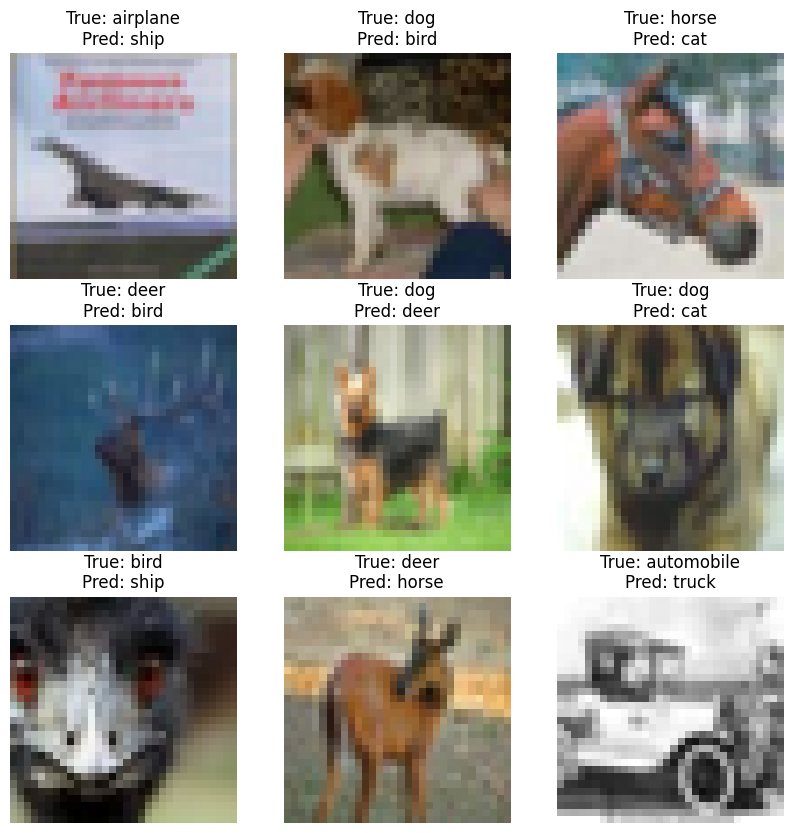

In [41]:
plt.figure(figsize=(10,10))

for i, idx in enumerate(wrong[:9]):
    plt.subplot(3,3,i+1)
    plt.imshow(x_test[idx])
    plt.title(f"True: {class_names[y_test[idx][0]]}\nPred: {class_names[pred_labels[idx]]}")
    plt.axis('off')

plt.show()

In [42]:
from sklearn.metrics import confusion_matrix

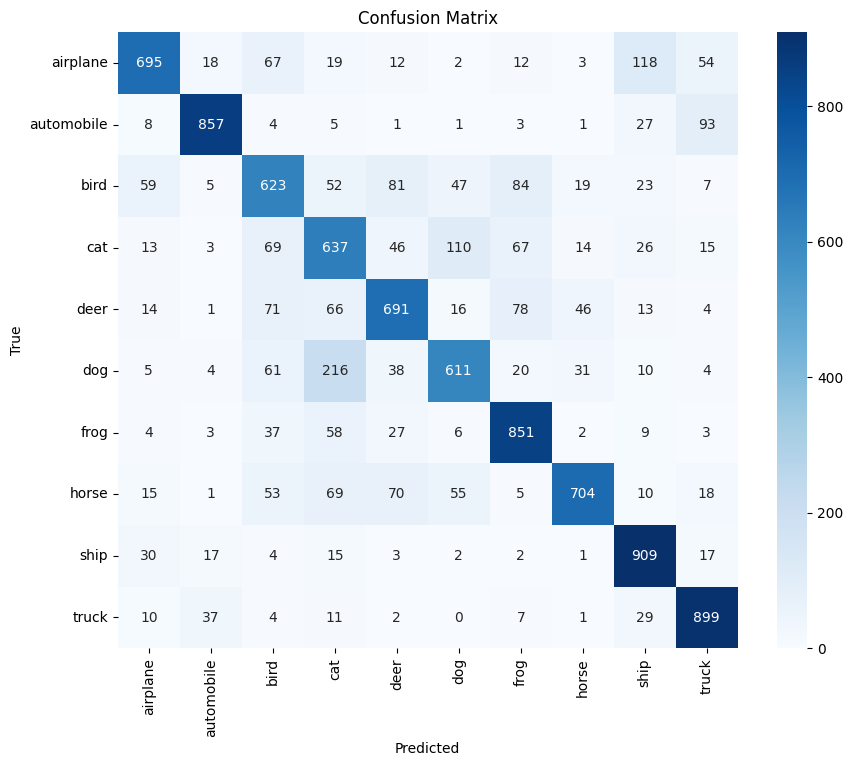

In [43]:
cm = confusion_matrix(y_test, pred_labels)

plt.figure(figsize=(10,8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names)

plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()

In [44]:
results = pd.DataFrame({
    'Model': ['Simple CNN', 'CNN + Dropout', 'CNN + BatchNorm'],
    'Accuracy': [test_acc_1, test_acc_2, test_acc_3]
})

print(results)

             Model  Accuracy
0       Simple CNN    0.7021
1    CNN + Dropout    0.7477
2  CNN + BatchNorm    0.6835
